# UPI Fraud Detection
Train and evaluate a fraud classifier on the supplied transaction dataset. The final 20% test split is stratified and held out from training. IDs, timestamps, and UPI addresses are excluded as features.

Run cells from top to bottom. The final cell saves the model for the Flask website.

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd()
if not (ROOT / 'app').exists() and (ROOT.parent / 'app').exists(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from app.model import DATA_PATH, train_model
print('Dataset:', DATA_PATH)
print('Exists:', DATA_PATH.exists())

Dataset: D:\UPI\archive\dataset.csv
Exists: True


In [2]:
import pandas as pd
df = pd.read_csv(DATA_PATH)
print('Shape:', df.shape)
print('Fraud counts:')
display(df['is_fraud'].value_counts().rename(index={0:'legitimate',1:'fraud'}))
display(df.head())

Shape: (250000, 20)
Fraud counts:


is_fraud
fraud         125016
legitimate    124984
Name: count, dtype: int64

,transaction id,timestamp,transaction type,merchant_category,amount (INR),transaction_status,sender_age_group,receiver_age_group,sender_state,sender_bank,receiver_bank,device_type,network_type,hour_of_day,day_of_week,is_weekend,sender_upi_id,receiver_upi_id,risk_score,is_fraud
0,TXN0000000001,2024-10-08 15:17:28,P2P,Entertainment,868,SUCCESS,26-35,18-25,Delhi,Axis,SBI,Android,4G,15,Tuesday,0,7608637542@okidfc,8649164205@okidfc,509.0,1
1,TXN0000000002,2024-04-11 06:56:00,P2M,Grocery,1011,SUCCESS,26-35,26-35,Uttar Pradesh,ICICI,Axis,iOS,4G,6,Thursday,0,9421126067@okhdfcbank,9200491309@okhdfcbank,535.5,1
2,TXN0000000003,2024-04-02 13:27:18,P2P,Grocery,477,SUCCESS,26-35,36-45,Karnataka,Yes Bank,PNB,Android,4G,13,Tuesday,0,6787846414@okaxis,8682311790@okidfc,303.5,0
3,TXN0000000004,2024-01-07 10:09:17,P2P,Fuel,2784,SUCCESS,26-35,26-35,Delhi,ICICI,PNB,Android,5G,10,Sunday,1,9143890026@okaxis,9017759644@oksbi,1442.0,1
4,TXN0000000005,2024-01-23 19:04:23,P2P,Shopping,990,SUCCESS,26-35,18-25,Delhi,Axis,Yes Bank,iOS,WiFi,19,Tuesday,0,9348747335@okidfc,9640238697@okhdfcbank,590.0,1


## Train and evaluate
Random forest uses balanced class weights to account for fraud class imbalance. All preprocessing is fitted within the training split through a scikit-learn pipeline.

In [3]:
metrics = train_model()
for name in ['accuracy','precision','recall','f1','roc_auc']:
    print(f'{name:>10}: {metrics[name]:.4f}')
print('Test rows:', metrics['test_rows'])
print('Fraud prevalence:', f"{metrics['fraud_rate']:.2%}")

  accuracy: 0.9298
 precision: 0.9309
    recall: 0.9285
        f1: 0.9297
   roc_auc: 0.9300
Test rows: 50000
Fraud prevalence: 50.01%


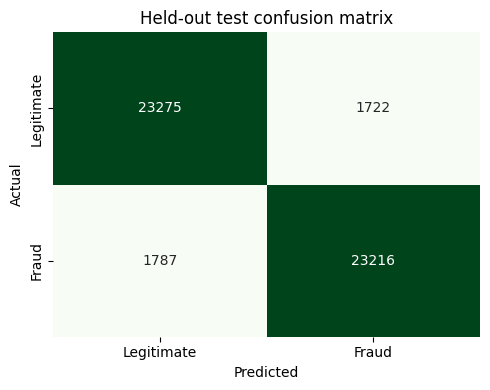

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
cm = metrics['confusion_matrix']
fig, ax = plt.subplots(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', cbar=False,
            xticklabels=['Legitimate','Fraud'], yticklabels=['Legitimate','Fraud'], ax=ax)
ax.set(xlabel='Predicted', ylabel='Actual', title='Held-out test confusion matrix')
plt.tight_layout()

In [5]:
report = pd.DataFrame(metrics['classification_report']).T
display(report.round(3))
print('Model saved to:', ROOT / 'app' / 'fraud_model.joblib')

,precision,recall,f1-score,support
0,0.929,0.931,0.93,24997.00
1,0.931,0.929,0.93,25003.00
accuracy,0.930,0.930,0.93,0.93
macro avg,0.930,0.930,0.93,50000.00
weighted avg,0.930,0.930,0.93,50000.00


Model saved to: d:\UPI\app\fraud_model.joblib


## Run the website
From a terminal in this folder run `python -m app.server`, then open http://127.0.0.1:5000. Use `python train.py` to retrain without opening this notebook.

This is a demonstration model. A prediction score is not a guarantee and should not be used alone to approve or block real payments.